# Business problem statement

A leading financial institution wants to develop an intelligent Anti-Money Laundering detection system using Artificial Neural Networks to identify suspicious financial transactions. The existing rule-based system generates a large number of false alerts and fails to detect sophisticated money laundering patterns. The bank wants to leverage historical transaction data and customer behavioral patterns to build a predictive model that can classify transactions as legitimate or suspicious, thereby improving detection rates, reducing false positives, and supporting regulatory compliance

# Project Objective

The primary objective is to build a binary classification model using ANN to identify potentially suspicious financial transactions.

Technical objectives:
1. Analyze historical banking transaction data.
2. Perform exploratory data analysis (EDA).
3. Identify important transaction-level and customer-level features.
4. Handle missing values and categorical variables.
5. Apply feature scaling and preprocessing.
6. Handle imbalanced transaction classes.
7. Build an ANN architecture using TensorFlow/Keras.
8. Train the model to distinguish legitimate and suspicious transactions.
9. Optimize the model using hyperparameter tuning.
10. Evaluate the model using appropriate classification metrics.
11. Develop a prediction interface for real-time transaction monitoring.

# Expected business outcomes

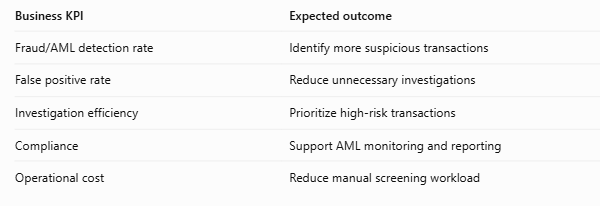

# Constraints

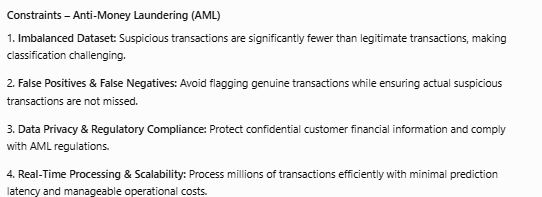

# 1.Data  Understanding

### 1. Data Collection

In [2]:
!pip install kagglehub

  Using cached certifi-2026.10.23-py3-none-any.whl.metadata (2.5 kB)
Using cached certifi-2026.10.23-py3-none-any.whl (135 kB)

  Attempting uninstall: certifi

    Found existing installation: certifi 2026.1.4

    Uninstalling certifi-2026.1.4:

      Successfully uninstalled certifi-2026.1.4

   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   -------------------------- ------------- 2/3 [kagglehub]
   ---------------------------------------- 3/3 [kagglehub]



ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.51.0 requires protobuf<7,>=3.20, but you have protobuf 7.36.2 which is incompatible.


In [2]:
import kagglehub
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [6]:
link = r'berkanoztas/synthetic-transaction-monitoring-dataset-aml'
kagglehub.dataset_download(link, output_dir=r'C:\Users\puppa\Documents\Innomatics\ANN', force_download=True)

100%|███████████████████████████████████████████████████████████████████████████████| 193M/193M [02:04<00:00, 1.63MB/s]

Extracting files...


'C:\\Users\\puppa\\Documents\\Innomatics\\ANN'

### 2. Data Description

In [3]:
df = pd.read_csv(r"C:\Users\puppa\Documents\Innomatics\ANN\SAML-D.csv")

In [4]:
df.shape # no of rows and columns

(9504852, 12)

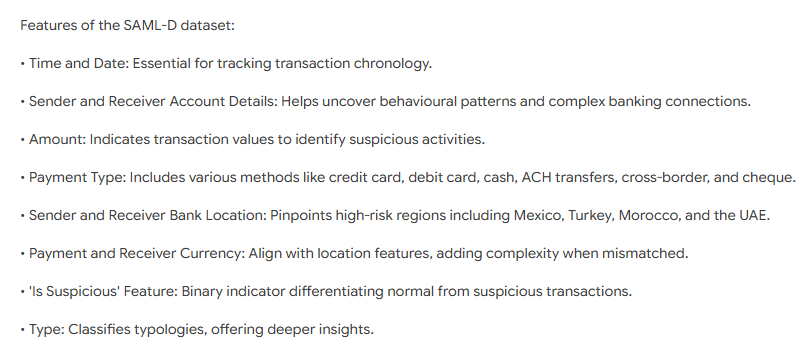

In [5]:
df.head()

,Time,Date,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Laundering_type
0,10:35:19,2022-10-07,8724731955,2769355426,1459.15,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits
1,10:35:20,2022-10-07,1491989064,8401255335,6019.64,UK pounds,Dirham,UK,UAE,Cross-border,0,Normal_Fan_Out
2,10:35:20,2022-10-07,287305149,4404767002,14328.44,UK pounds,UK pounds,UK,UK,Cheque,0,Normal_Small_Fan_Out
3,10:35:21,2022-10-07,5376652437,9600420220,11895.00,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Fan_In
4,10:35:21,2022-10-07,9614186178,3803336972,115.25,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits


.outputs= Is_laundering,laundering_type

.inputs - Date, Sender_account,Receiver_account,payment_currencies,sender_bank_location,receiver_back_location,payment_type

In [6]:
df.dtypes

Time                       object
Date                       object
Sender_account              int64
Receiver_account            int64
Amount                    float64
Payment_currency           object
Received_currency          object
Sender_bank_location       object
Receiver_bank_location     object
Payment_type               object
Is_laundering               int64
Laundering_type            object
dtype: object

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9504852 entries, 0 to 9504851
Data columns (total 12 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   Time                    object 
 1   Date                    object 
 2   Sender_account          int64  
 3   Receiver_account        int64  
 4   Amount                  float64
 5   Payment_currency        object 
 6   Received_currency       object 
 7   Sender_bank_location    object 
 8   Receiver_bank_location  object 
 9   Payment_type            object 
 10  Is_laundering           int64  
 11  Laundering_type         object 
dtypes: float64(1), int64(3), object(8)
memory usage: 870.2+ MB


# 2.Data preparation

### 1. Exploratory Data understanding

#### Univarient Analysis

In [8]:
df.isna().sum()

Time                      0
Date                      0
Sender_account            0
Receiver_account          0
Amount                    0
Payment_currency          0
Received_currency         0
Sender_bank_location      0
Receiver_bank_location    0
Payment_type              0
Is_laundering             0
Laundering_type           0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Sender_account,9504852.0,5.006619e+09,2.885814e+09,9018.00,2.513133e+09,5.001017e+09,7.505051e+09,9.999987e+09
Receiver_account,9504852.0,5.006006e+09,2.884763e+09,9018.00,2.513219e+09,5.002572e+09,7.502397e+09,9.999971e+09
Amount,9504852.0,8.762968e+03,2.561495e+04,3.73,2.143688e+03,6.113720e+03,1.045846e+04,1.261850e+07
Is_laundering,9504852.0,1.038733e-03,3.221263e-02,0.00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00


In [11]:
df.columns

Index(['Time', 'Date', 'Sender_account', 'Receiver_account', 'Amount',
       'Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type', 'Is_laundering',
       'Laundering_type'],
      dtype='object')

In [12]:
df['Amount'].mean()

np.float64(8762.967600927232)

In [13]:
df['Payment_type'].value_counts()

Payment_type
Credit card        2012909
Debit card         2012103
Cheque             2011419
ACH                2008807
Cross-border        933931
Cash Withdrawal     300477
Cash Deposit        225206
Name: count, dtype: int64

In [14]:
df['Payment_currency'].value_counts(normalize = True) #

Payment_currency
UK pounds          0.957331
Euro               0.012327
Turkish lira       0.002945
Swiss franc        0.002892
Dirham             0.002868
Pakistani rupee    0.002861
Naira              0.002856
US dollar          0.002742
Yen                0.002689
Moroccan dirham    0.002672
Mexican Peso       0.002615
Albanian lek       0.002607
Indian rupee       0.002594
Name: proportion, dtype: float64

In [15]:
df['Received_currency'].value_counts(normalize =True)

Received_currency
UK pounds          0.924123
Euro               0.024399
Pakistani rupee    0.004839
Yen                0.004820
Moroccan dirham    0.004813
Albanian lek       0.004812
Mexican Peso       0.004761
Naira              0.004739
Indian rupee       0.004604
US dollar          0.004594
Swiss franc        0.004517
Dirham             0.004503
Turkish lira       0.004476
Name: proportion, dtype: float64

In [16]:
df['Sender_bank_location'].value_counts(normalize = True)

Sender_bank_location
UK             0.966147
Turkey         0.002199
Switzerland    0.002157
Pakistan       0.002141
UAE            0.002113
Nigeria        0.002107
Spain          0.002040
Germany        0.002026
USA            0.002002
Italy          0.001988
France         0.001968
Japan          0.001943
Morocco        0.001940
Austria        0.001899
Mexico         0.001858
Albania        0.001857
India          0.001851
Netherlands    0.001764
Name: proportion, dtype: float64

In [17]:

df['Receiver_bank_location'].value_counts(normalize = True)

Receiver_bank_location
UK             0.932643
Pakistan       0.004101
Austria        0.004087
Albania        0.004080
Japan          0.004075
Morocco        0.004072
Germany        0.004055
France         0.004052
Mexico         0.004038
Nigeria        0.004027
Netherlands    0.003926
Spain          0.003923
India          0.003886
USA            0.003877
Italy          0.003842
Switzerland    0.003796
UAE            0.003777
Turkey         0.003744
Name: proportion, dtype: float64

In [18]:
df['Payment_type'].value_counts()

Payment_type
Credit card        2012909
Debit card         2012103
Cheque             2011419
ACH                2008807
Cross-border        933931
Cash Withdrawal     300477
Cash Deposit        225206
Name: count, dtype: int64

<Axes: ylabel='count'>

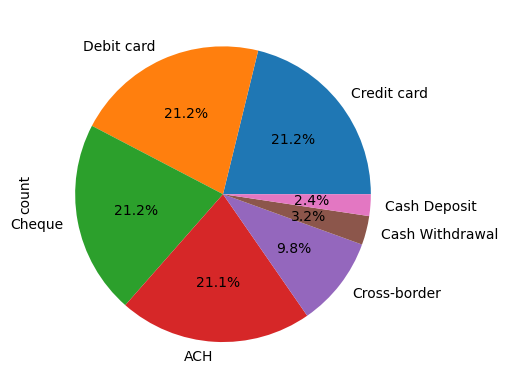

In [19]:
df['Payment_type'].value_counts().plot(kind ='pie',autopct ='%.1f%%')

In [20]:
df['Is_laundering'].value_counts()#

Is_laundering
0    9494979
1       9873
Name: count, dtype: int64

<Axes: xlabel='Is_laundering'>

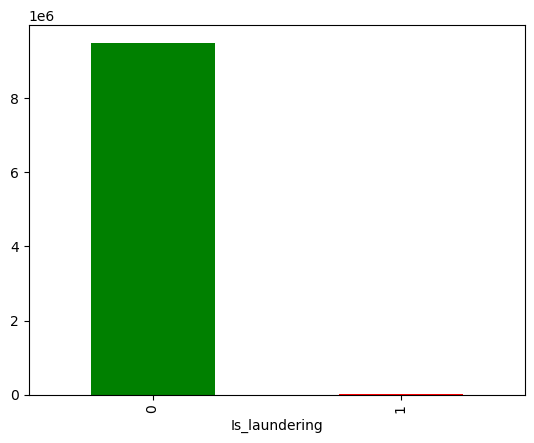

In [21]:
df['Is_laundering'].value_counts().plot(kind ='bar',color = ['green','red']) # the data set is imbalanced

<Axes: xlabel='Laundering_type'>

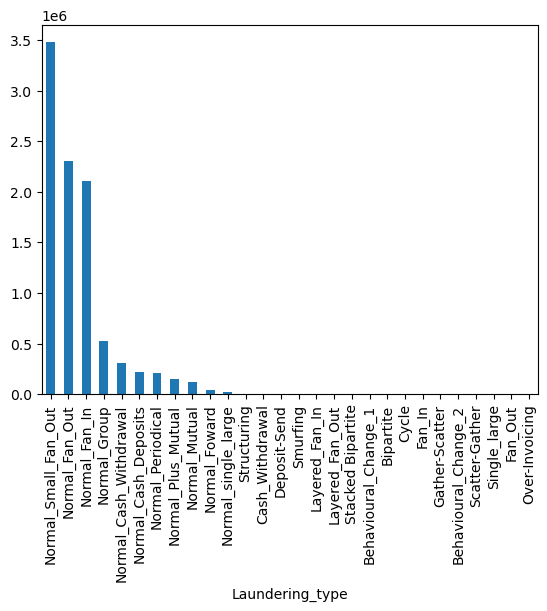

In [22]:
df['Laundering_type'].value_counts().plot(kind = 'bar')

<Axes: xlabel='Laundering_type'>

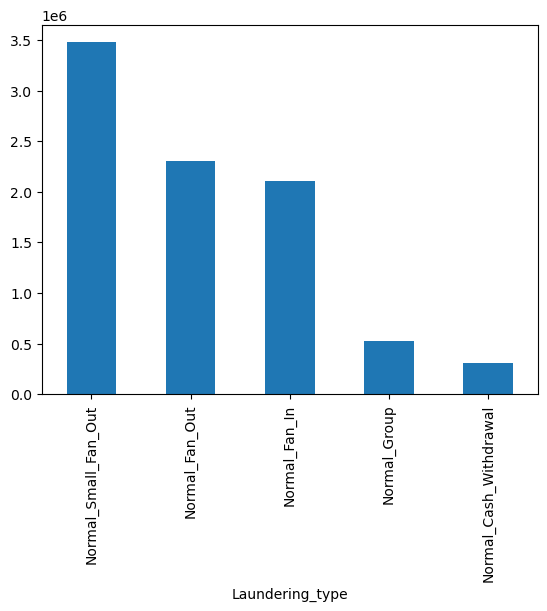

In [23]:
df['Laundering_type'].value_counts().nlargest(5).plot(kind = 'bar')

#### Bivariate Analysis

In [24]:

df.columns

Index(['Time', 'Date', 'Sender_account', 'Receiver_account', 'Amount',
       'Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type', 'Is_laundering',
       'Laundering_type'],
      dtype='object')

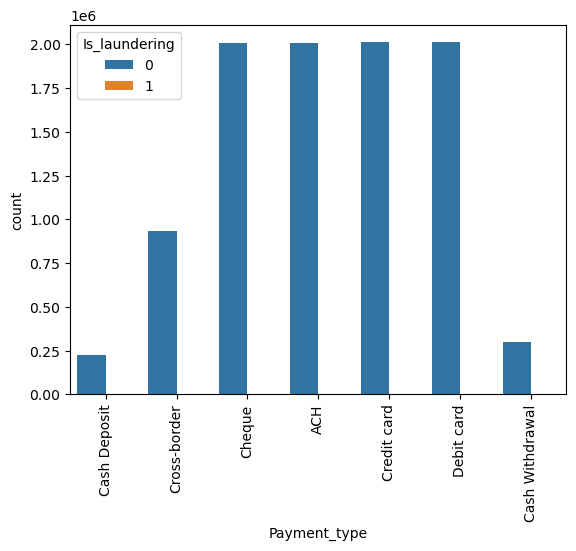

In [25]:
sns.countplot(x = df['Payment_type'],hue = df['Is_laundering'])
plt.xticks(rotation = 90)
plt.show()

In [26]:
df.columns

Index(['Time', 'Date', 'Sender_account', 'Receiver_account', 'Amount',
       'Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type', 'Is_laundering',
       'Laundering_type'],
      dtype='object')

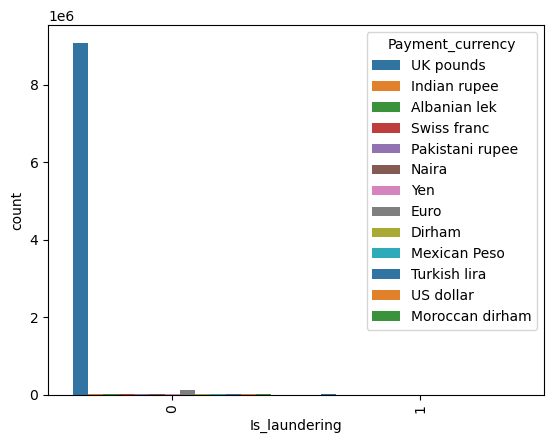

In [27]:
sns.countplot(hue = df['Payment_currency'],x= df['Is_laundering'],palette ='tab10')
plt.xticks(rotation = 90)
plt.show()

In [28]:
df.columns

Index(['Time', 'Date', 'Sender_account', 'Receiver_account', 'Amount',
       'Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type', 'Is_laundering',
       'Laundering_type'],
      dtype='object')

<Axes: xlabel='Is_laundering', ylabel='Amount'>

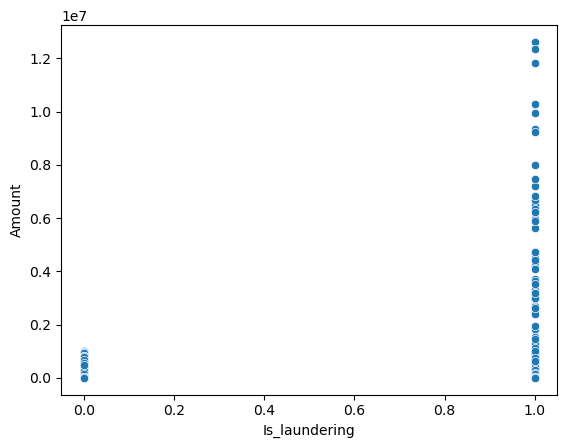

In [29]:
sns.scatterplot(x = df['Is_laundering'],y = df['Amount'])

In [30]:
# Perform Bivariate for more insights

In [31]:
df.dtypes

Time                       object
Date                       object
Sender_account              int64
Receiver_account            int64
Amount                    float64
Payment_currency           object
Received_currency          object
Sender_bank_location       object
Receiver_bank_location     object
Payment_type               object
Is_laundering               int64
Laundering_type            object
dtype: object

In [32]:
df['Sender_account'] = df['Sender_account'].astype('str')
df['Receiver_account'] = df['Receiver_account'].astype('str')

In [33]:
df['Date'] = df['Date'].astype('datetime64[ns]')

In [34]:
df['Date'].value_counts()

Date
2023-02-09    36645
2023-02-01    35910
2023-02-06    35038
2023-02-22    34566
2022-12-23    34156
              ...  
2022-12-31    25808
2022-10-30    25298
2022-10-23    23719
2022-10-07    20892
2023-08-23     8400
Name: count, Length: 321, dtype: int64

In [35]:
df['Date'].dt.year

0          2022
1          2022
2          2022
3          2022
4          2022
           ... 
9504847    2023
9504848    2023
9504849    2023
9504850    2023
9504851    2023
Name: Date, Length: 9504852, dtype: int32

In [36]:
df.drop(columns =['Time','Date','Laundering_type','Sender_account','Receiver_account'],inplace = True)

In [37]:
df = df.sample(n=100000,random_state = 23)

In [38]:
df.shape

(100000, 7)

In [39]:
X= df.drop(columns = ['Is_laundering'])
y = df['Is_laundering']

In [41]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from imblearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [42]:
cat_columns = X.select_dtypes(include = ['object']).columns
numerical_cols  = X.select_dtypes(exclude = ['object']).columns

In [43]:
cat_columns

Index(['Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type'],
      dtype='object')

In [44]:
cat_transformer   =Pipeline([('OHE',OneHotEncoder(dtype = 'int'))])

In [45]:
numerical_transformer = Pipeline([('Scaling',StandardScaler())])

In [47]:
preprocess = ColumnTransformer([('cat_transformer', cat_transformer, cat_columns),
('numerical_transfomer',numerical_transformer, numerical_cols)])

In [48]:
preprocess

,transformers,"[('cat_transformer', ...), ('numerical_transfomer', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,categories,'auto'
,drop,None
,sparse_output,True


In [50]:
from collections import Counter

In [51]:
Counter(y)

Counter({0: 99887, 1: 113})

In [52]:
from imblearn.over_sampling import SMOTE

In [53]:
resampling = Pipeline([('Preoricessing',preprocess),('Smote',SMOTE(random_state = 23))])

In [56]:
resampling

,steps,"[('Preoricessing', ...), ('Smote', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat_transformer', ...), ('numerical_transfomer', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [57]:
X_s,y_s = resampling.fit_resample(X,y)

In [58]:
Counter(y_s)

Counter({0: 99887, 1: 99887})

# Model Building

In [86]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,Dense,BatchNormalization,Dropout

In [87]:
X_s.shape[1]

70

In [88]:
model = Sequential()

#input layers

model.add(Input(shape = (X_s.shape[1],)))

#input layers

model.add(Dense(units = 16,activation='relu'))
model.add(Dense(units = 8,activation='relu'))
model.add(Dense(units = 4,activation='relu'))
model.add(Dense(units = 1,activation='relu'))

model.add(Dense(units = 1,activation  = 'sigmoid'))

In [89]:
model.compile(optimizer ='adam',loss = 'binary_crossentropy',metrics =  ['accuracy'])

In [90]:
history  = model.fit(X_s,y_s,epochs = 30,validation_split = 0.2)

Epoch 1/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 33s 6ms/step - accuracy: 0.7823 - loss: 0.5038 - val_accuracy: 0.6041 - val_loss: 0.6818
Epoch 2/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 31s 6ms/step - accuracy: 0.8019 - loss: 0.4240 - val_accuracy: 0.5846 - val_loss: 0.5817
Epoch 3/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 26s 5ms/step - accuracy: 0.8090 - loss: 0.3912 - val_accuracy: 0.6069 - val_loss: 0.5873
Epoch 4/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 29s 6ms/step - accuracy: 0.8106 - loss: 0.3786 - val_accuracy: 0.6034 - val_loss: 0.5657
Epoch 5/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 40s 5ms/step - accuracy: 0.8133 - loss: 0.3718 - val_accuracy: 0.5607 - val_loss: 0.6271
Epoch 6/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 27s 5ms/step - accuracy: 0.8156 - loss: 0.3681 - val_accuracy: 0.5955 - val_loss: 0.5147
Epoch 7/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 28s 6ms/step - accuracy: 0.8182 - loss: 0.3649 - val_accuracy: 0.5559 - val_loss: 0.6652
Epoch 8/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 27s 5ms/step - accuracy: 0.8181 - loss: 0

# Hyper parameter tuning

In [91]:
import optuna
from tensorflow.keras.optimizers import RMSprop,SGD,Adam
from tensorflow.keras.callbacks import EarlyStopping

In [92]:
def objective(trial):
    n_layers = trial.suggest_int('n_layers', 1, 4)
    learning_rate = trial.suggest_float('learning_rate', 0.0001, 0.1)
    batch_size = trial.suggest_categorical('batch_size', [16, 32, 64, 128, 256])
    optimizer_name = trial.suggest_categorical('optimizer', ['adam', 'rmsprop', 'sgd'])

    # Building the model
    model = Sequential()

    # Add the Input layer ONCE before the loop
    model.add(Input(shape=(X_s.shape[1],)))

    for i in range(n_layers):
        units = trial.suggest_int('units_layer', 2, 32)
        dropout_rate = trial.suggest_float('dropout_layer', 0.0, 0.6)
        activation = trial.suggest_categorical('activatation', ['relu', 'tanh', 'sigmoid'])

        # Only add Dense and Dropout inside the loop
        model.add(Dense(units=units, activation=activation))
        model.add(Dropout(rate=dropout_rate))
        
    model.add(Dense(1, activation='sigmoid'))

    if optimizer_name == 'adam':
        optimizer = Adam(learning_rate=learning_rate)
    elif optimizer_name == 'rmsprop':
        optimizer = RMSprop(learning_rate=learning_rate)
    else:
        optimizer = SGD(learning_rate=learning_rate)

    model.compile(
        optimizer=optimizer, 
        loss='binary_crossentropy', 
        metrics=['accuracy']
    )

    early_stop = EarlyStopping(
        monitor='val_loss', 
        patience=5, 
        restore_best_weights=True
    )

    history = model.fit(
        X_s, y_s, 
        validation_split = 0.2,
        epochs=100, 
        batch_size=batch_size,
        callbacks=[early_stop]
    )

    best_loss = min(history.history['val_loss'])
    trial.set_user_attr('best_val_loss', float(best_loss))
    return best_loss

In [93]:
study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler())

[I 2026-11-11 12:03:11,760] A new study created in memory with name: no-name-d2fc2828-748c-40c5-880f-f89dbea23b04


In [94]:
study.optimize(objective,n_trials=30)

Epoch 1/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.7718 - loss: 0.4811 - val_accuracy: 0.7766 - val_loss: 0.4800
Epoch 2/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7886 - loss: 0.4290 - val_accuracy: 0.5367 - val_loss: 0.8755
Epoch 3/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7948 - loss: 0.4189 - val_accuracy: 0.6052 - val_loss: 0.6409
Epoch 4/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7971 - loss: 0.4136 - val_accuracy: 0.5558 - val_loss: 0.6511
Epoch 5/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7984 - loss: 0.4110 - val_accuracy: 0.8026 - val_loss: 0.5546
Epoch 6/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7992 - loss: 0.4090 - val_accuracy: 0.8563 - val_loss: 0.4765
Epoch 7/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7988 - loss: 0.4098 - val_accuracy: 0.9099 - val_loss: 0.3274
Epoch 8/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8018 - loss: 0.4019 - val_accu

[I 2026-11-11 12:03:59,493] Trial 0 finished with value: 0.2539946436882019 and parameters: {'n_layers': 2, 'learning_rate': 0.09607052741293882, 'batch_size': 256, 'optimizer': 'rmsprop', 'units_layer': 11, 'dropout_layer': 0.016132842527394553, 'activatation': 'tanh'}. Best is trial 0 with value: 0.2539946436882019.


Epoch 1/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - accuracy: 0.7131 - loss: 0.5958 - val_accuracy: 0.4742 - val_loss: 0.8514
Epoch 2/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.7318 - loss: 0.5819 - val_accuracy: 0.5183 - val_loss: 0.7371
Epoch 3/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.7305 - loss: 0.5826 - val_accuracy: 0.3987 - val_loss: 0.8697
Epoch 4/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.7338 - loss: 0.5838 - val_accuracy: 0.3245 - val_loss: 0.7861
Epoch 5/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.7340 - loss: 0.5880 - val_accuracy: 0.5150 - val_loss: 0.8101
Epoch 6/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.7344 - loss: 0.5868 - val_accuracy: 0.4929 - val_loss: 0.7541
Epoch 7/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.7335 - loss: 0.5871 - val_accuracy: 0.5671 - val_loss: 0.6269
Epoch 8/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.7335 - los

[I 2026-11-11 12:07:00,136] Trial 1 finished with value: 0.5204763412475586 and parameters: {'n_layers': 3, 'learning_rate': 0.027786118604187574, 'batch_size': 64, 'optimizer': 'rmsprop', 'units_layer': 17, 'dropout_layer': 0.5655870959552818, 'activatation': 'relu'}. Best is trial 0 with value: 0.2539946436882019.


Epoch 1/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 14s 5ms/step - accuracy: 0.7772 - loss: 0.5020 - val_accuracy: 0.5652 - val_loss: 0.6937
Epoch 2/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.7862 - loss: 0.4857 - val_accuracy: 0.6103 - val_loss: 0.6190
Epoch 3/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.7888 - loss: 0.4796 - val_accuracy: 0.6146 - val_loss: 0.6131
Epoch 4/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 0.7904 - loss: 0.4745 - val_accuracy: 0.6067 - val_loss: 0.7024
Epoch 5/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 0.7920 - loss: 0.4719 - val_accuracy: 0.5260 - val_loss: 0.7895
Epoch 6/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.7931 - loss: 0.4699 - val_accuracy: 0.5947 - val_loss: 0.7709
Epoch 7/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.7933 - loss: 0.4692 - val_accuracy: 0.5433 - val_loss: 0.7780
Epoch 8/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.7942 - 

[I 2026-11-11 12:08:32,470] Trial 2 finished with value: 0.613089382648468 and parameters: {'n_layers': 3, 'learning_rate': 0.0037492121263041503, 'batch_size': 64, 'optimizer': 'adam', 'units_layer': 5, 'dropout_layer': 0.04749342652676902, 'activatation': 'tanh'}. Best is trial 0 with value: 0.2539946436882019.


... (50 outputs left out)

Epoch 1/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.7541 - loss: 0.5446 - val_accuracy: 0.6207 - val_loss: 0.7560
Epoch 2/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7761 - loss: 0.4778 - val_accuracy: 0.6006 - val_loss: 0.5162
Epoch 3/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7811 - loss: 0.4609 - val_accuracy: 0.6217 - val_loss: 0.6099
Epoch 4/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7858 - loss: 0.4555 - val_accuracy: 0.5144 - val_loss: 0.8213
Epoch 5/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7835 - loss: 0.4567 - val_accuracy: 0.5272 - val_loss: 0.8494
Epoch 6/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7886 - loss: 0.4466 - val_accuracy: 0.7364 - val_loss: 0.4900
Epoch 7/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7863 - loss: 0.4476 - val_accuracy: 0.7519 - val_loss: 0.6495
Epoch 8/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7854 - loss: 0.4494 - val_accu

[I 2026-11-11 12:52:53,309] Trial 28 finished with value: 0.4899652302265167 and parameters: {'n_layers': 3, 'learning_rate': 0.07813712464237367, 'batch_size': 256, 'optimizer': 'rmsprop', 'units_layer': 16, 'dropout_layer': 0.083224635885224, 'activatation': 'tanh'}. Best is trial 0 with value: 0.2539946436882019.


Epoch 1/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.7700 - loss: 0.5198 - val_accuracy: 0.5797 - val_loss: 0.6264
Epoch 2/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7795 - loss: 0.4942 - val_accuracy: 0.5602 - val_loss: 0.7820
Epoch 3/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7797 - loss: 0.4848 - val_accuracy: 0.5998 - val_loss: 0.8050
Epoch 4/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7799 - loss: 0.4821 - val_accuracy: 0.6194 - val_loss: 0.7185
Epoch 5/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7815 - loss: 0.4785 - val_accuracy: 0.5518 - val_loss: 0.5989
Epoch 6/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7807 - loss: 0.4788 - val_accuracy: 0.5114 - val_loss: 0.7329
Epoch 7/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7822 - loss: 0.4763 - val_accuracy: 0.5844 - val_loss: 0.6812
Epoch 8/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7824 - loss: 0.4748 - val_accu

[I 2026-11-11 12:53:49,282] Trial 29 finished with value: 0.5314651727676392 and parameters: {'n_layers': 2, 'learning_rate': 0.06640003341927442, 'batch_size': 256, 'optimizer': 'rmsprop', 'units_layer': 6, 'dropout_layer': 0.17915005965596287, 'activatation': 'tanh'}. Best is trial 0 with value: 0.2539946436882019.


In [96]:
study.best_params

{'n_layers': 2,
 'learning_rate': 0.09607052741293882,
 'batch_size': 256,
 'optimizer': 'rmsprop',
 'units_layer': 11,
 'dropout_layer': 0.016132842527394553,
 'activatation': 'tanh'}

In [97]:
model = Sequential()

#input layers

model.add(Input(shape = (X_s.shape[1],)))

#input layers

model.add(Dense(units = 256,activation='relu'))
model.add(Dense(units = 256,activation='relu'))


model.add(Dense(units = 1,activation  = 'tanh'))

In [98]:
model.compile(optimizer ='rmsprop',loss = 'binary_crossentropy',metrics =  ['accuracy'])

In [ ]:
history  = model.fit(X_s,y_s,epochs = 30,validation_split = 0.2)

Epoch 1/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 33s 6ms/step - accuracy: 0.7940 - loss: 0.5245 - val_accuracy: 0.5783 - val_loss: 2.5367
Epoch 2/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 30s 6ms/step - accuracy: 0.7987 - loss: 0.5974 - val_accuracy: 0.8958 - val_loss: 0.7430
Epoch 3/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 33s 7ms/step - accuracy: 0.7928 - loss: 0.7044 - val_accuracy: 0.6128 - val_loss: 2.5205
Epoch 4/30
1037/4995 ━━━━━━━━━━━━━━━━━━━━ 21s 5ms/step - accuracy: 0.7842 - loss: 0.7167

In [83]:
import pickle
import joblib

In [84]:
model.save('AIML.keras')

In [85]:
joblib.dump(preprocess,'preprocessor')

['preprocessor']